# Gold Layer: Heatmap Explorer

Reads the tables produced by `build_gold.ipynb` and draws:

1. **Hour × Route** heatmap (average delay, % on time, number of visits) and the same at 15-minute resolution
2. **Weekday × Hour** heatmap
3. **Hour × Stop** heatmap (top stops, or the stops of one route)
4. **Spatial** map of stops (coloured by delay, sized by visits)

Everything comes from `gold_heat_*` / `gold_stop_map`. Cells with fewer than `MIN_VALID` valid observations are left blank so thin data doesn't look like a signal.

In [2]:
import os
from pathlib import Path
import duckdb
import numpy as np
import matplotlib.pyplot as plt

GOLD_DIR  = Path(os.environ.get("GOLD_DIR", "../../tables/parquet_2026-10-24/gold-layer-parquet"))
MIN_VALID = 5      # hide heatmap cells with fewer valid observations than this
TOP_N     = 25     # routes / stops shown per heatmap
ROUTE_FOR_STOP_VIEW = None   # e.g. "3"; None = busiest route

con = duckdb.connect()
def q(sql):
    return con.execute(sql).df()
def t(name):
    return f"read_parquet('{(GOLD_DIR / (name + '.parquet')).as_posix()}')"

meta = q(f"SELECT * FROM {t('gold_meta')}").set_index("key")["value"]
print("Service dates:", meta["service_dates"], "| on-time rule:", meta["on_time_rule"])

def heatmap(pivot, title, cbar, cmap="RdYlGn_r", fmt=None, center=None, figsize=(13, 7)):
    fig, ax = plt.subplots(figsize=figsize)
    data = pivot.values.astype(float)
    kw = {}
    if center is not None:
        m = np.nanmax(np.abs(data - center)) if np.isfinite(data).any() else 1
        kw = dict(vmin=center - m, vmax=center + m)
    im = ax.imshow(np.ma.masked_invalid(data), aspect="auto", cmap=cmap, **kw)
    ax.set_xticks(range(pivot.shape[1])); ax.set_xticklabels(pivot.columns, rotation=90 if pivot.shape[1] > 30 else 0, fontsize=8)
    ax.set_yticks(range(pivot.shape[0])); ax.set_yticklabels(pivot.index, fontsize=8)
    ax.set_title(title); plt.colorbar(im, ax=ax, label=cbar)
    if fmt and data.size <= 600:
        for (i, j), v in np.ndenumerate(data):
            if np.isfinite(v): ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=6)
    plt.tight_layout(); plt.show()

Service dates: 2026-10-24,2026-10-25,2026-10-26,2026-10-27 | on-time rule: -60 <= delay_s < 300


## 1. Hour × Route

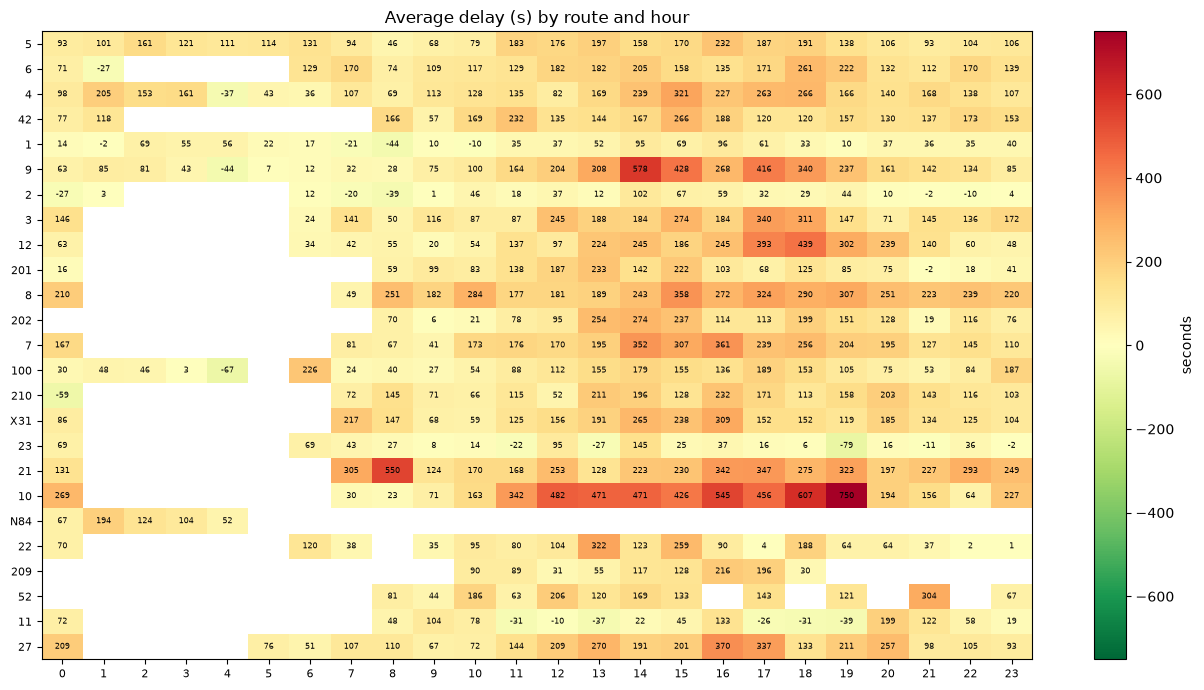

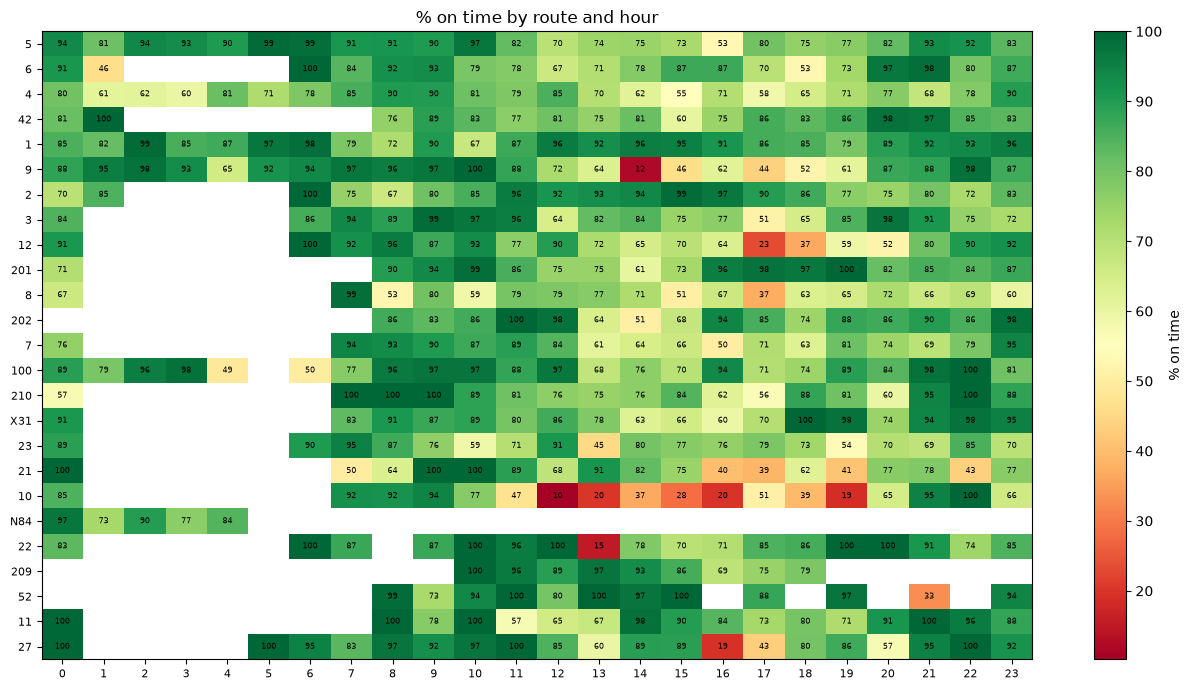

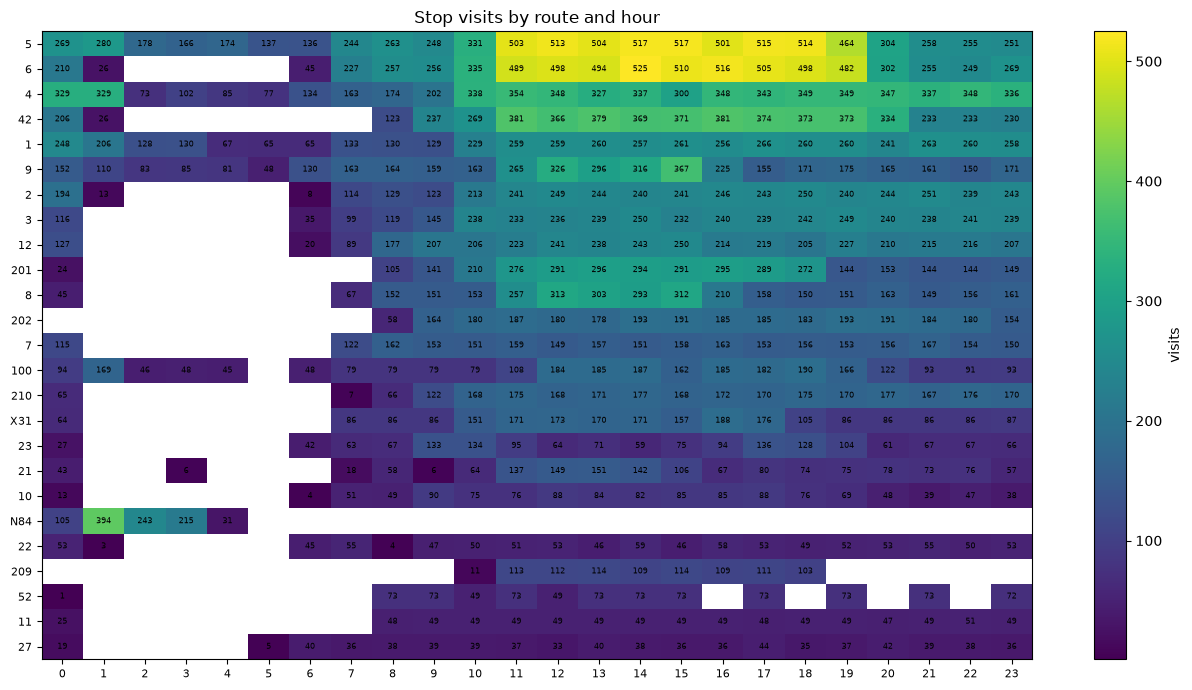

In [3]:
rh = q(f"SELECT * FROM {t('gold_heat_route_hour')} WHERE local_hour >= 0")
top_routes = rh.groupby("route_short_name")["n_calls"].sum().nlargest(TOP_N).index
rh = rh[rh.route_short_name.isin(top_routes)]
masked = rh.where(rh.n_valid >= MIN_VALID)   # thin cells -> NaN

def piv(df, val, idx="route_short_name", col="local_hour"):
    p = df.pivot_table(index=idx, columns=col, values=val, aggfunc="first")
    return p.reindex(index=[r for r in top_routes if r in p.index]) if idx == "route_short_name" else p

heatmap(piv(masked.assign(route_short_name=rh.route_short_name, local_hour=rh.local_hour), "avg_delay_s"),
        "Average delay (s) by route and hour", "seconds", cmap="RdYlGn_r", center=0, fmt="{:.0f}")
heatmap(piv(masked.assign(route_short_name=rh.route_short_name, local_hour=rh.local_hour), "pct_on_time") * 100,
        "% on time by route and hour", "% on time", cmap="RdYlGn", fmt="{:.0f}")
heatmap(piv(rh, "n_calls"), "Stop visits by route and hour", "visits", cmap="viridis", fmt="{:.0f}")

### 15-minute bins for one route

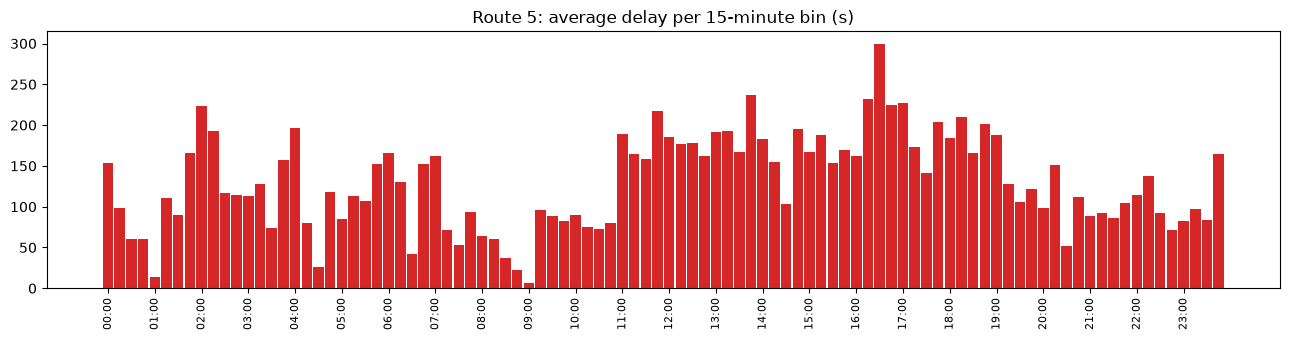

In [4]:
rq = q(f"SELECT * FROM {t('gold_heat_route_quarter')} WHERE local_quarter >= 0")
route = ROUTE_FOR_STOP_VIEW or rq.groupby("route_short_name")["n_calls"].sum().idxmax()
sub = rq[(rq.route_short_name == route)]
sub = sub.where(sub.n_valid >= MIN_VALID).dropna(subset=["avg_delay_s"])
ax = plt.figure(figsize=(13, 3.5)).gca()
ax.bar(sub.local_quarter, sub.avg_delay_s, width=0.9, color=np.where(sub.avg_delay_s > 0, "tab:red", "tab:green"))
ax.set_xticks(range(0, 96, 4)); ax.set_xticklabels([f"{h:02d}:00" for h in range(24)], rotation=90, fontsize=8)
ax.set_title(f"Route {route}: average delay per 15-minute bin (s)"); plt.tight_layout(); plt.show()

## 2. Weekday × Hour

Weekdays present in the data: ['Friday', 'Saturday', 'Sunday'] | service dates per weekday: {'Friday': np.int64(1), 'Saturday': np.int64(2), 'Sunday': np.int64(2)}


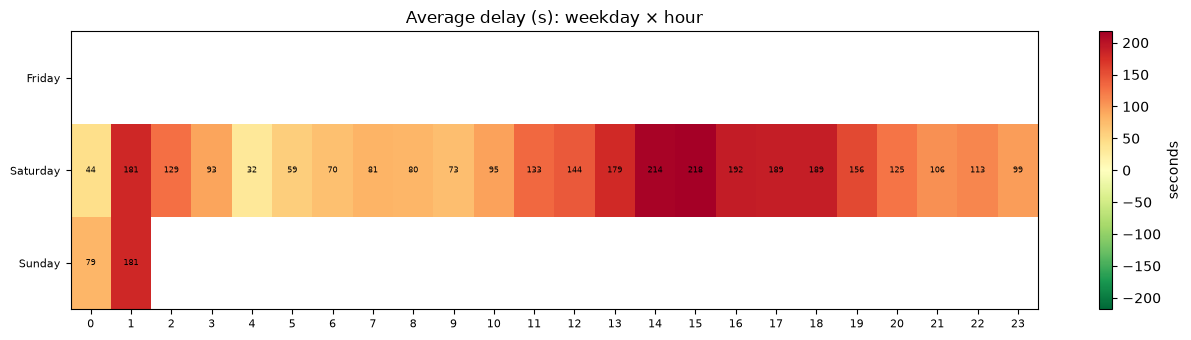

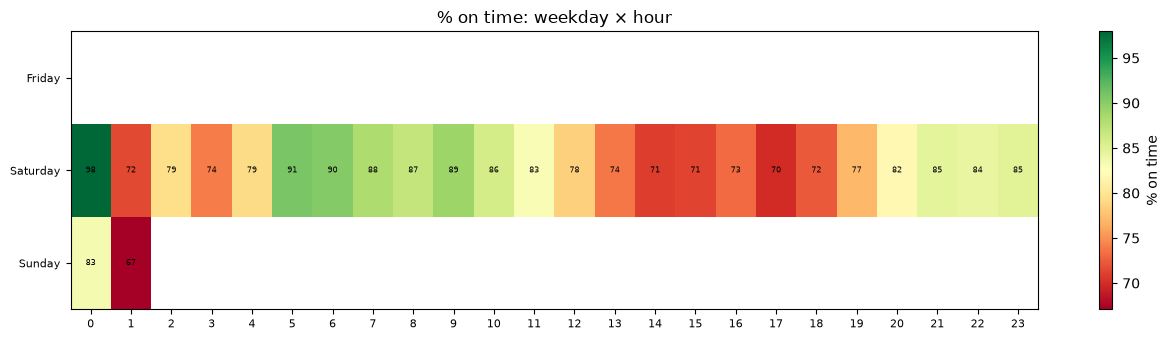

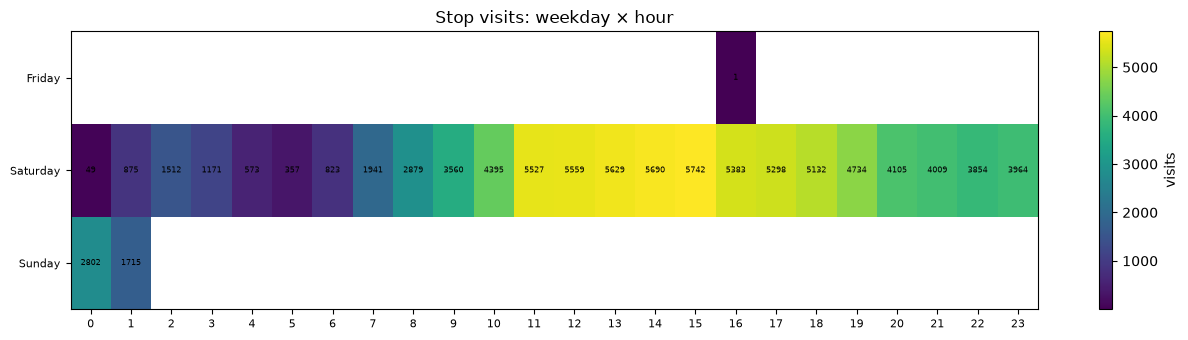

In [5]:
wh = q(f"SELECT * FROM {t('gold_heat_weekday_hour')} WHERE local_hour >= 0 AND weekday >= 0")
print("Weekdays present in the data:", sorted(wh.weekday_name.unique(), key=lambda n: wh[wh.weekday_name == n].weekday.iloc[0]),
      "| service dates per weekday:", dict(wh.groupby("weekday_name").n_service_dates.max()))
wm = wh.where(wh.n_valid >= MIN_VALID)
order = wh.sort_values("weekday").weekday_name.unique()
def wpiv(df, val): return df.assign(weekday_name=wh.weekday_name, local_hour=wh.local_hour).pivot_table(index="weekday_name", columns="local_hour", values=val, aggfunc="first").reindex(order)
heatmap(wpiv(wm, "avg_delay_s"), "Average delay (s): weekday × hour", "seconds", center=0, fmt="{:.0f}", figsize=(13, 3.5))
heatmap(wpiv(wm, "pct_on_time") * 100, "% on time: weekday × hour", "% on time", cmap="RdYlGn", fmt="{:.0f}", figsize=(13, 3.5))
heatmap(wpiv(wh, "n_calls"), "Stop visits: weekday × hour", "visits", cmap="viridis", fmt="{:.0f}", figsize=(13, 3.5))

## 3. Station–Hour (stops × hour)

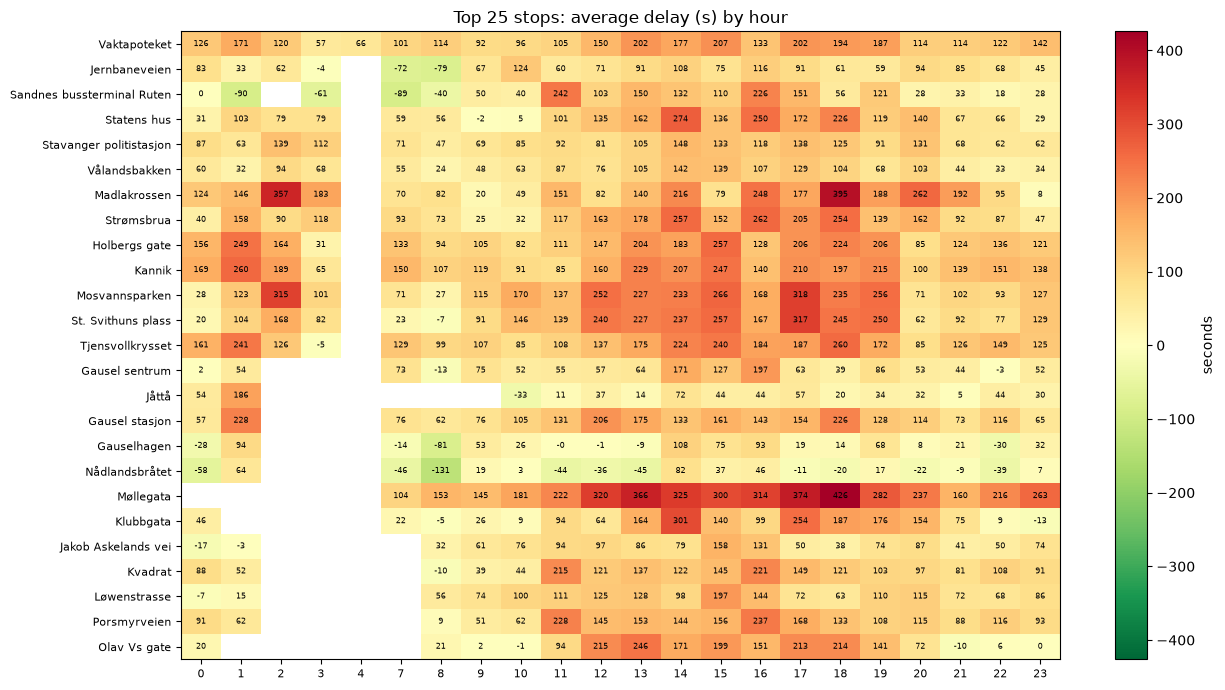

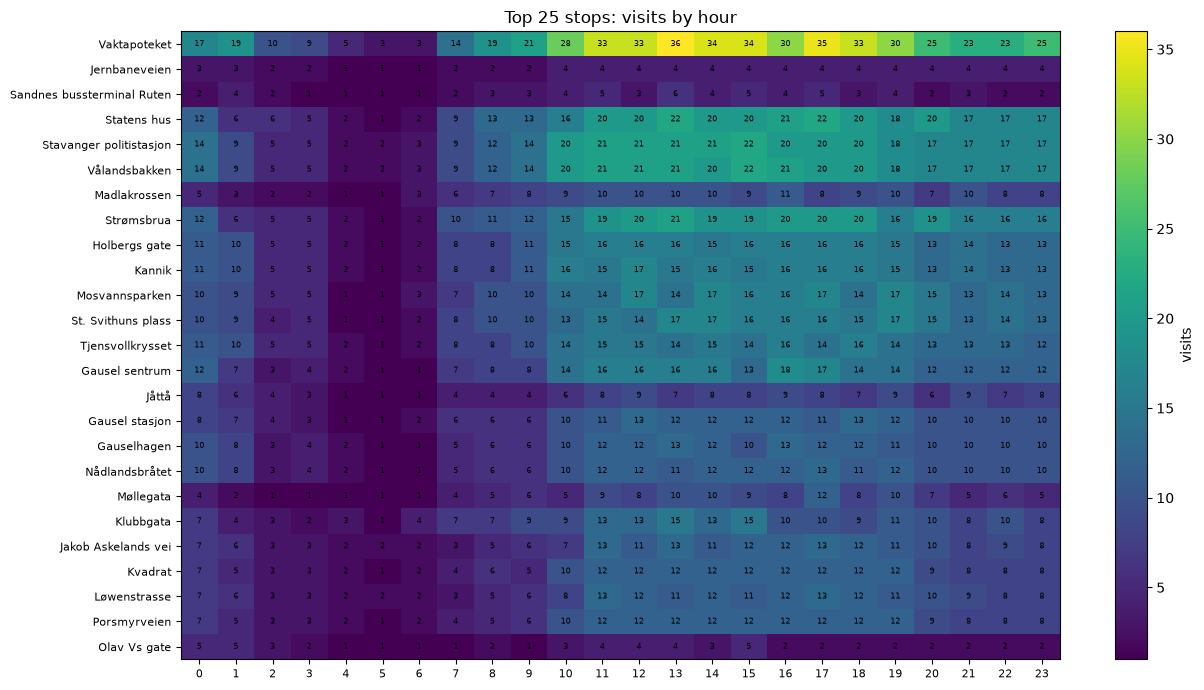

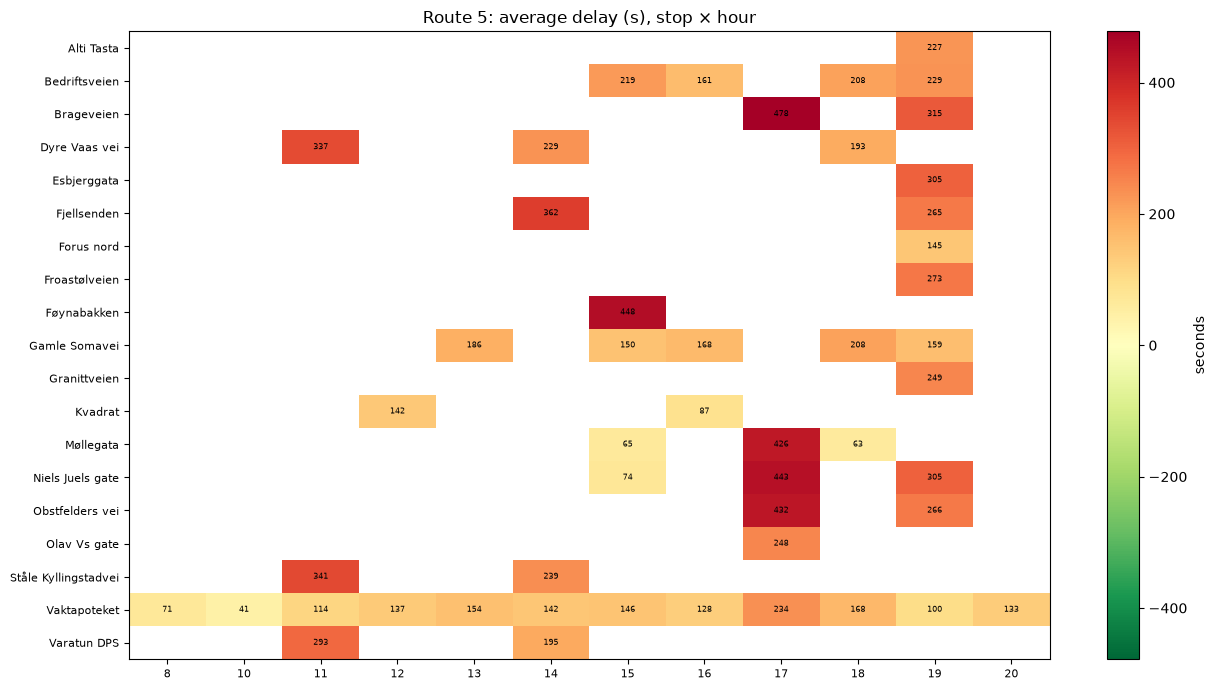

In [6]:
# (a) busiest stops overall
sh = q(f"SELECT * FROM {t('gold_heat_stop_hour')} WHERE local_hour >= 0")
top_stops = sh.groupby("stop_name")["n_calls"].sum().nlargest(TOP_N).index
s1 = sh[sh.stop_name.isin(top_stops)]
s1m = s1.where(s1.n_valid >= MIN_VALID)
def spiv(df, base, val, idx="stop_name"): return df.assign(**{idx: base[idx], "local_hour": base.local_hour}).pivot_table(index=idx, columns="local_hour", values=val, aggfunc="first").reindex([x for x in top_stops if x in set(base[idx])])
heatmap(spiv(s1m, s1, "avg_delay_s"), f"Top {TOP_N} stops: average delay (s) by hour", "seconds", center=0, fmt="{:.0f}")
heatmap(spiv(s1, s1, "n_calls"), f"Top {TOP_N} stops: visits by hour", "visits", cmap="viridis", fmt="{:.0f}")

# (b) one route: its stops x hour
rs = q(f"SELECT * FROM {t('gold_heat_route_stop_hour')} WHERE local_hour >= 0 AND route_short_name = '{route}'")
top_stops_r = rs.groupby("stop_name")["n_calls"].sum().nlargest(TOP_N).index
rs = rs[rs.stop_name.isin(top_stops_r)]
rsm = rs.where(rs.n_valid >= MIN_VALID)
heatmap(rsm.assign(stop_name=rs.stop_name, local_hour=rs.local_hour).pivot_table(index="stop_name", columns="local_hour", values="avg_delay_s", aggfunc="first"),
        f"Route {route}: average delay (s), stop × hour", "seconds", center=0, fmt="{:.0f}")

## 4. Spatial map of stops

1,662 stops with coordinates and >= 5 valid visits


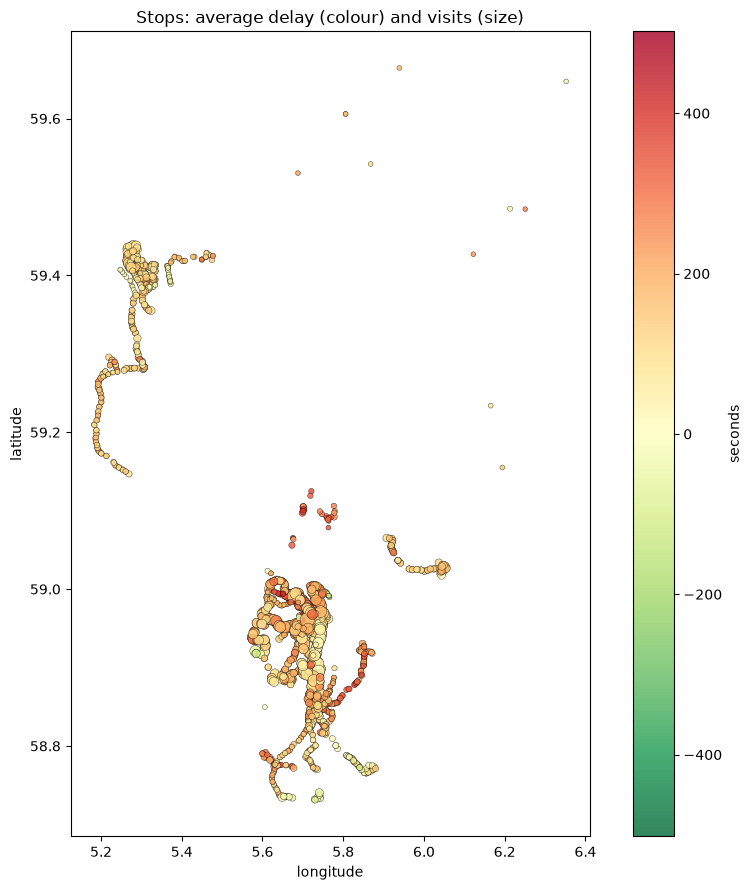

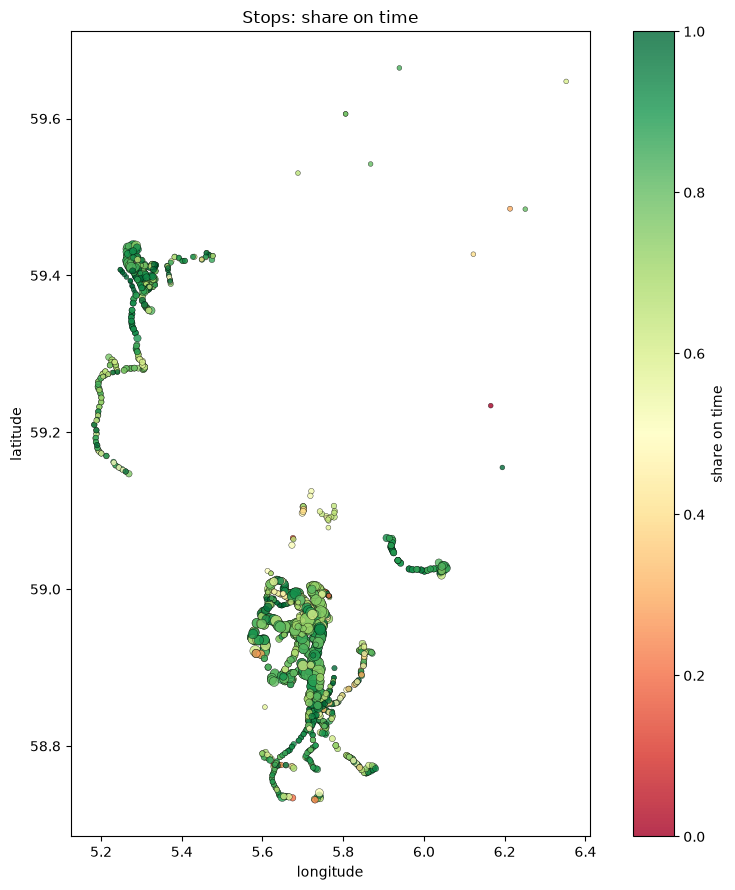

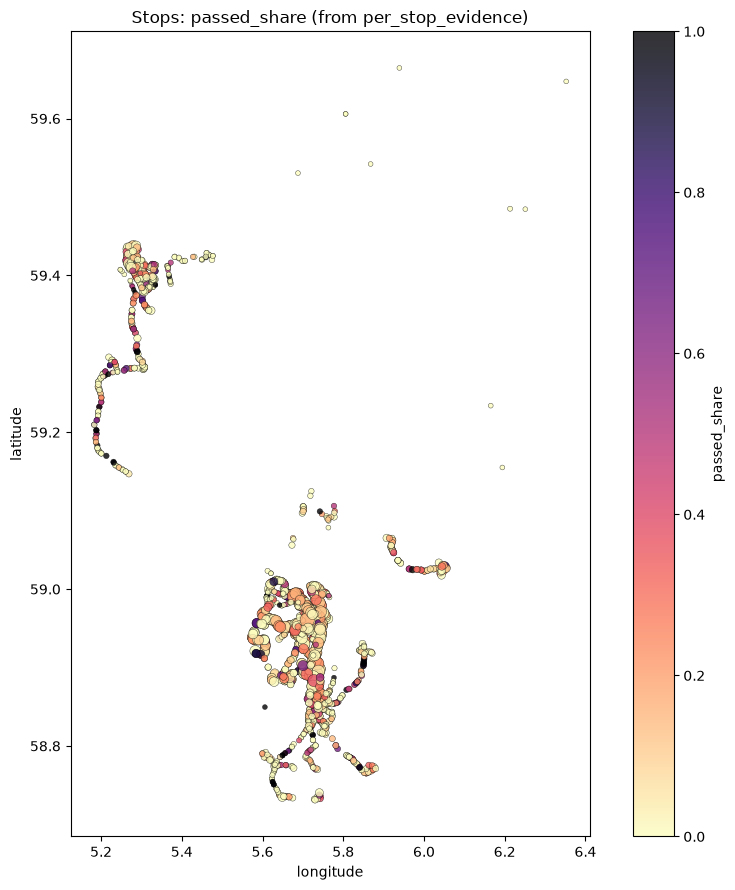

In [7]:
sm = q(f"SELECT * FROM {t('gold_stop_map')} WHERE stop_lat IS NOT NULL AND stop_lon IS NOT NULL")
sm = sm[sm.n_valid >= MIN_VALID]
print(f"{len(sm):,} stops with coordinates and >= {MIN_VALID} valid visits")

def stopmap(col, title, cmap, label, center=None):
    fig, ax = plt.subplots(figsize=(9, 9))
    kw = {}
    if center is not None:
        m = np.nanmax(np.abs(sm[col] - center)); kw = dict(vmin=center - m, vmax=center + m)
    sc = ax.scatter(sm.stop_lon, sm.stop_lat, c=sm[col], s=10 + 190 * sm.n_valid / sm.n_valid.max(), cmap=cmap, alpha=.8, edgecolor="k", linewidth=.3, **kw)
    ax.set_aspect(1 / np.cos(np.radians(sm.stop_lat.mean())))   # keep map proportions at this latitude
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_title(title)
    plt.colorbar(sc, ax=ax, label=label); plt.tight_layout(); plt.show()

stopmap("avg_delay_s", "Stops: average delay (colour) and visits (size)", "RdYlGn_r", "seconds", center=0)
stopmap("pct_on_time", "Stops: share on time", "RdYlGn", "share on time")
if "passed_share" in sm and sm.passed_share.notna().any():
    sm = sm[sm.passed_share.notna()]
    stopmap("passed_share", "Stops: passed_share (from per_stop_evidence)", "magma_r", "passed_share")

### Not included (not in the current data)
`vehicle_positions` is not among the Silver files, so there is no GPS-ping density map or dwell/congestion map. `stop_gps_status` has per-stop GPS summaries only, not raw positions.